# 04 · Aplicação Estratégica — inteligência para a política pública

Este notebook responde às perguntas de negócio do desafio:

| Pergunta | Técnica |
|---|---|
| Quais fatores mais impactam a alfabetização? | SHAP / permutação (notebook 03) + coeficientes do modelo de risco |
| Quais municípios apresentam maior risco educacional? | Modelo supervisionado de risco municipal + agregação do modelo de alunos |
| Quais regiões possuem padrões semelhantes? | Clusterização K-Means + PCA (não supervisionado) |
| Como prever municípios que podem não atingir metas futuras? | Classificador treinado em 2023→2024, aplicado em 2024→**2025** |
| Quais variáveis possuem maior influência nos modelos? | Síntese das três lentes de interpretabilidade |

In [1]:
import sys, warnings, json
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config, main
from src.modeling import strategic
from src.visualization import plots as vp

vp.set_style()
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.max_columns", 30)

resumo = main.step_strategic(k=4)
cv = pd.read_csv(config.REPORTS_DIR / "risco_meta_cv.csv")
ranking = pd.read_csv(config.REPORTS_DIR / "ranking_risco_municipios_2025.csv", dtype={"id_municipio": str})
clusters = pd.read_csv(config.REPORTS_DIR / "clusters_municipios.csv", dtype={"id_municipio": str})
coef = pd.read_csv(config.REPORTS_DIR / "risco_meta_importancia.csv")

## 1. Modelo de risco: o município vai deixar de atingir a meta do próximo ano?

* **Unidade:** município (rede municipal). **Alvo:** `taxa(T) < meta(T)`.
* **Treino:** features de 2023 → resultado de 2024 (5.232 municípios com meta e resultado). **Aplicação:** features de 2024 → **meta de 2025**.
* **Validação:** CV estratificada (5 folds) **e** CV agrupada por UF — esta última testa se o modelo generaliza para estados que não viu.

In [2]:
cv[["modelo", "validacao", "roc_auc_cv", "roc_auc_cv_desvio", "roc_auc_treino", "balanced_accuracy_cv", "recall_cv", "precision_cv"]]

,modelo,validacao,roc_auc_cv,roc_auc_cv_desvio,roc_auc_treino,balanced_accuracy_cv,recall_cv,precision_cv
0,logistic,estratificada,0.763,0.008,0.769,0.693,0.676,0.671
1,logistic,agrupada por UF,0.707,0.084,0.770,0.648,0.598,0.661
2,random_forest,estratificada,0.787,0.009,0.854,0.696,0.651,0.688
3,random_forest,agrupada por UF,0.621,0.062,0.856,0.580,0.490,0.585


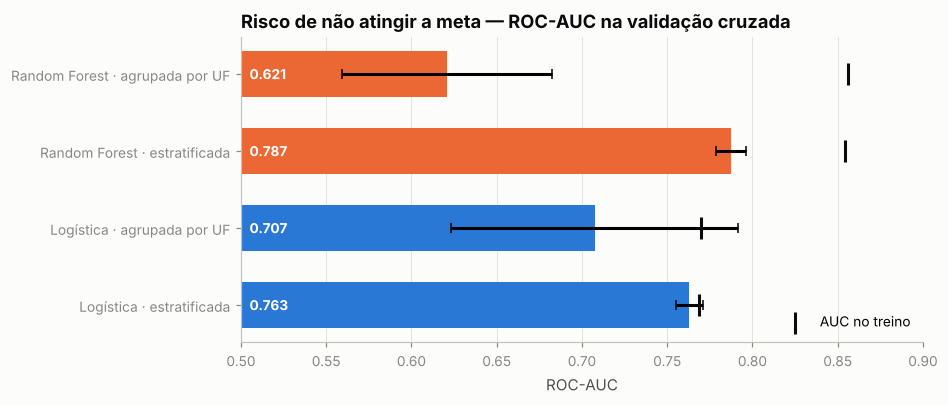

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.6))
lab = cv["modelo"].map({"logistic": "Logística", "random_forest": "Random Forest"}) + " · " + cv["validacao"]
cores = [vp.CAT[0] if "Logística" in l else vp.CAT[1] for l in lab]
ax.barh(lab, cv["roc_auc_cv"], xerr=cv["roc_auc_cv_desvio"], color=cores, height=0.6, capsize=3)
ax.scatter(cv["roc_auc_treino"], lab, marker="|", s=200, color=vp.INK, label="AUC no treino", zorder=3)
for i, v in enumerate(cv["roc_auc_cv"]): ax.text(0.505, i, f"{v:.3f}", va="center", color="white", fontsize=9, fontweight="bold")
ax.set(xlim=(0.5, 0.9), title="Risco de não atingir a meta — ROC-AUC na validação cruzada", xlabel="ROC-AUC")
ax.grid(axis="y", visible=False); ax.legend(loc="lower right")
vp.save(fig, "estr_risco_cv"); plt.show()

**Escolha do algoritmo:** a Random Forest tem AUC maior na CV estratificada, mas **despenca na CV por UF** e mostra grande gap
treino−teste — ela "decora" padrões de estados específicos (por exemplo, o choque das enchentes do RS em 2024). A **regressão logística**
perde pouco na CV estratificada, generaliza muito melhor para UFs não vistas e tem coeficientes interpretáveis. Para uma ferramenta de
política pública, **robustez e transparência valem mais que 2–3 pontos de AUC** → modelo escolhido: **regressão logística**.

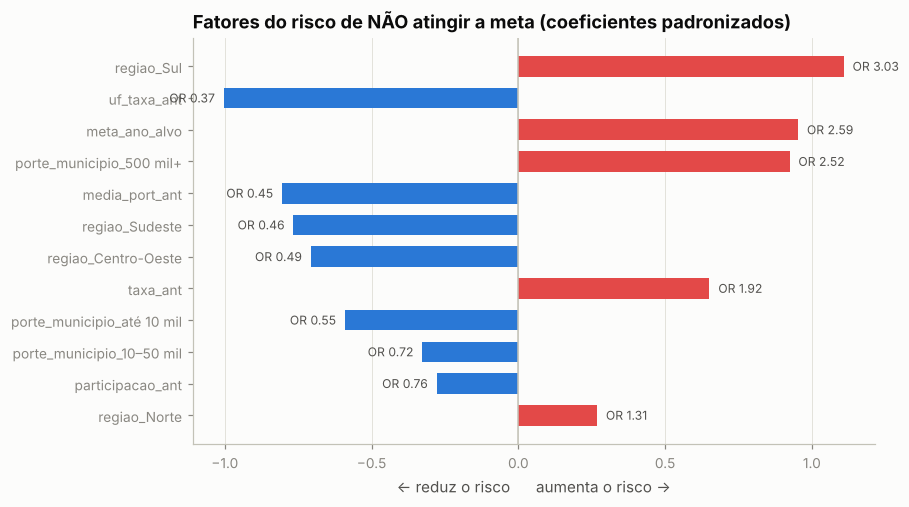

In [4]:
top = coef.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(top["feature"], top["coeficiente"], color=[vp.CAT[7] if c > 0 else vp.CAT[0] for c in top["coeficiente"]], height=0.65)
ax.axvline(0, color=vp.AXIS, lw=1); ax.grid(axis="y", visible=False)
for i, (c, o) in enumerate(zip(top["coeficiente"], top["odds_ratio_por_dp"])):
    ax.text(c + (0.03 if c > 0 else -0.03), i, f"OR {o:.2f}", va="center", ha="left" if c > 0 else "right", fontsize=8, color=vp.INK2)
ax.set(title="Fatores do risco de NÃO atingir a meta (coeficientes padronizados)", xlabel="← reduz o risco      aumenta o risco →")
vp.save(fig, "estr_risco_coeficientes"); plt.show()

Leitura (variáveis padronizadas — OR = razão de chances por 1 desvio-padrão): **contexto estadual forte** (taxa da UF em 2023) e
**proficiência média** alta protegem; **metas mais ambiciosas** e **grandes cidades (500 mil+)** elevam o risco; municípios pequenos e com
**maior participação** têm menos risco. O sinal positivo de `taxa_ant` (com proficiência controlada) reflete a regressão à média vista na EDA.

## 2. Quais municípios apresentam maior risco educacional para 2025?

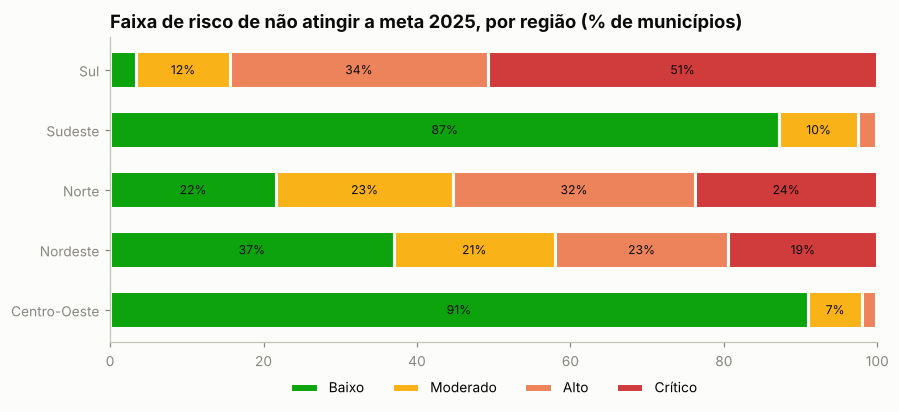

faixa_risco
Baixo       2608
Moderado     799
Alto         945
Crítico     1000
Name: count, dtype: int64


In [5]:
ordem = ["Baixo", "Moderado", "Alto", "Crítico"]
dist = pd.crosstab(ranking["regiao"], ranking["faixa_risco"]).reindex(columns=ordem).fillna(0)
dist_pct = dist.div(dist.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(9, 3.6))
left = np.zeros(len(dist_pct))
for f in ordem:
    ax.barh(dist_pct.index, dist_pct[f], left=left, color=vp.STATUS[f], label=f, height=0.62, edgecolor=vp.SURFACE, linewidth=2)
    for i, (l, v) in enumerate(zip(left, dist_pct[f])):
        if v >= 7: ax.text(l + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=8, color=vp.INK)
    left += dist_pct[f].values
ax.set(title="Faixa de risco de não atingir a meta 2025, por região (% de municípios)", xlim=(0, 100))
ax.grid(False); ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.08))
vp.save(fig, "estr_risco_regioes"); plt.show()
print(ranking["faixa_risco"].value_counts().reindex(ordem))

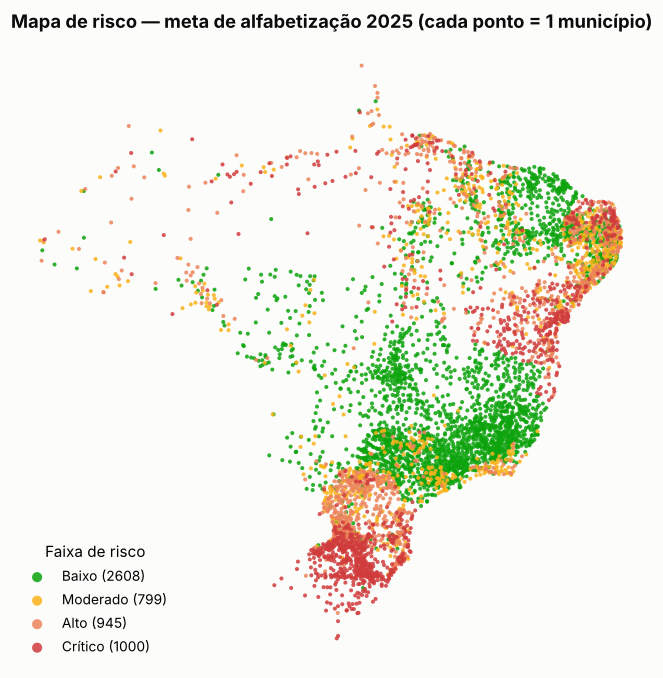

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 7.5))
for f in ordem:
    d = ranking.merge(clusters[["id_municipio", "latitude", "longitude"]], on="id_municipio")
    d = d[d.faixa_risco == f]
    ax.scatter(d.longitude, d.latitude, s=7, color=vp.STATUS[f], label=f"{f} ({len(d)})", edgecolors="none", alpha=0.85)
ax.set_aspect("equal"); ax.grid(False); ax.set_xticks([]); ax.set_yticks([])
for sp in ax.spines.values(): sp.set_visible(False)
ax.set_title("Mapa de risco — meta de alfabetização 2025 (cada ponto = 1 município)")
ax.legend(loc="lower left", markerscale=2.5, title="Faixa de risco")
vp.save(fig, "estr_mapa_risco"); plt.show()

In [7]:
cols = ["nome_municipio", "sigla_uf", "porte_municipio", "taxa_2024", "meta_2025", "esforco_necessario", "participacao_2024", "prob_nao_atingir_meta_2025"]
print("Top 15 municípios com maior risco (rede municipal):")
display(ranking[cols].head(15))
print("Top 10 fora do RS (para evitar que o choque de 2024 domine a lista):")
display(ranking[ranking.sigla_uf != "RS"][cols].head(10))

Top 15 municípios com maior risco (rede municipal):


,nome_municipio,sigla_uf,porte_municipio,taxa_2024,meta_2025,esforco_necessario,participacao_2024,prob_nao_atingir_meta_2025
0,Arroio do Padre,RS,até 10 mil,18.200,80.000,61.800,84.620,0.996
1,Caxias do Sul,RS,500 mil+,43.200,72.560,29.360,82.630,0.995
2,Canela,RS,10–50 mil,42.200,79.060,36.860,78.530,0.994
3,Espumoso,RS,10–50 mil,39.100,80.000,40.900,81.250,0.993
4,Sentinela do Sul,RS,até 10 mil,23.500,75.700,52.200,85.710,0.993
5,Jaquirana,RS,até 10 mil,25.600,72.130,46.530,71.790,0.993
6,Nova Palma,RS,até 10 mil,35.900,80.000,44.100,82.350,0.992
7,Sério,RS,até 10 mil,11.100,80.000,68.900,100.000,0.992
8,São Marcos,RS,10–50 mil,38.300,80.000,41.700,87.610,0.992
9,Sapiranga,RS,50–100 mil,41.100,74.990,33.890,83.080,0.992


Top 10 fora do RS (para evitar que o choque de 2024 domine a lista):


,nome_municipio,sigla_uf,porte_municipio,taxa_2024,meta_2025,esforco_necessario,participacao_2024,prob_nao_atingir_meta_2025
61,Santo Antônio,RN,10–50 mil,23.560,70.800,47.240,85.390,0.986
124,Dom Macedo Costa,BA,até 10 mil,52.380,80.000,27.620,91.300,0.979
131,Novo Aripuanã,AM,10–50 mil,50.990,80.000,29.010,75.620,0.978
144,Botuporã,BA,10–50 mil,47.370,67.880,20.510,71.250,0.977
145,Carnaúba dos Dantas,RN,até 10 mil,29.880,70.150,40.270,82.860,0.977
173,Pindaí,BA,10–50 mil,38.330,73.830,35.500,95.240,0.975
182,Caibi,SC,até 10 mil,27.300,76.830,49.530,73.810,0.974
208,São Gonçalo do Amarante,RN,100–500 mil,32.480,61.370,28.890,76.620,0.970
228,Érico Cardoso,BA,10–50 mil,37.210,71.830,34.620,93.480,0.968
239,Monte do Carmo,TO,até 10 mil,19.710,73.100,53.390,81.010,0.967


In [8]:
# Municípios grandes (100 mil+ hab.) em risco alto/crítico — maior número de crianças afetadas
grandes = ranking[ranking.porte_municipio.isin(["100–500 mil", "500 mil+"]) & ranking.faixa_risco.isin(["Alto", "Crítico"])]
print(f"{len(grandes)} municípios com 100 mil+ habitantes em risco alto/crítico")
grandes[cols].head(15)

122 municípios com 100 mil+ habitantes em risco alto/crítico


,nome_municipio,sigla_uf,porte_municipio,taxa_2024,meta_2025,esforco_necessario,participacao_2024,prob_nao_atingir_meta_2025
1,Caxias do Sul,RS,500 mil+,43.200,72.560,29.360,82.630,0.995
14,Bento Gonçalves,RS,100–500 mil,50.800,78.150,27.350,84.270,0.991
20,Santa Maria,RS,100–500 mil,39.700,70.020,30.320,77.890,0.990
32,Gravataí,RS,100–500 mil,41.000,68.910,27.910,77.250,0.989
34,São Leopoldo,RS,100–500 mil,37.200,64.510,27.310,71.700,0.988
48,Novo Hamburgo,RS,100–500 mil,36.000,68.070,32.070,83.600,0.987
74,Uruguaiana,RS,100–500 mil,47.300,67.360,20.060,74.640,0.984
77,Santa Cruz do Sul,RS,100–500 mil,43.800,69.700,25.900,83.690,0.984
80,Cachoeirinha,RS,100–500 mil,40.600,65.200,24.600,76.700,0.984
96,Viamão,RS,100–500 mil,38.900,65.740,26.840,83.340,0.982


## 3. Quais regiões possuem padrões semelhantes? (clusterização)

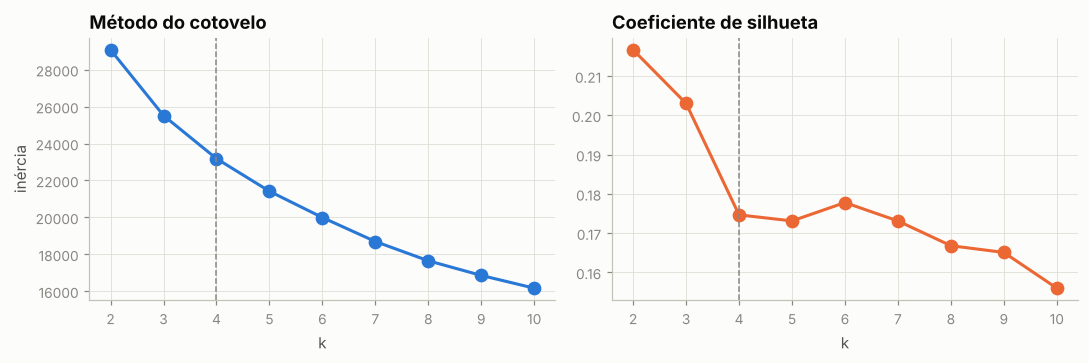

In [9]:
ks = pd.read_csv(config.REPORTS_DIR / "clusters_escolha_k.csv")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].plot(ks.k, ks.inercia, marker="o", ms=8, color=vp.CAT[0]); axes[0].set(title="Método do cotovelo", xlabel="k", ylabel="inércia")
axes[1].plot(ks.k, ks.silhouette, marker="o", ms=8, color=vp.CAT[1]); axes[1].set(title="Coeficiente de silhueta", xlabel="k")
for ax in axes: ax.axvline(4, ls="--", color=vp.MUTED, lw=1)
fig.tight_layout(); vp.save(fig, "estr_escolha_k"); plt.show()

A silhueta é baixa para qualquer *k* (perfis municipais formam um contínuo, não grupos isolados) e varia pouco entre 4 e 7.
Escolhemos **k = 4** pelo cotovelo e pela **acionabilidade**: quatro perfis são fáceis de traduzir em estratégias de política pública.

In [10]:
feat = ["taxa_2024", "evolucao_23_24", "participacao_2024", "gap_meta_2030", "populacao_2019", "pib_per_capita_2010", "dist_capital_km", "prob_nao_atingir_meta_2025"]
perfil = clusters.groupby("cluster")[feat].median()
perfil["municipios"] = clusters.cluster.value_counts()
ordem_c = perfil["taxa_2024"].sort_values().index.tolist()
NOMES = dict(zip(ordem_c, ["A · Vulnerável (baixo e em queda)", "B · Urbano mediano (baixa participação)",
                           "C · Interior intermediário (estagnado)", "D · Referência (alto e em ascensão)"]))
clusters["perfil"] = clusters["cluster"].map(NOMES)
perfil.index = perfil.index.map(NOMES)
perfil = perfil.loc[[NOMES[c] for c in ordem_c]]
perfil.round(1)

,taxa_2024,evolucao_23_24,participacao_2024,gap_meta_2030,populacao_2019,pib_per_capita_2010,dist_capital_km,prob_nao_atingir_meta_2025,municipios
cluster,,,,,,,,,
A · Vulnerável (baixo e em queda),41.100,-3.200,91.900,38.900,"12,449.000","4,529.400",197.300,0.700,1457
B · Urbano mediano (baixa participação),57.400,2.000,86.400,21.900,"48,949.000","14,380.500",120.200,0.500,953
C · Interior intermediário (estagnado),67.600,-0.700,90.900,12.400,"7,507.000","12,406.300",383.300,0.500,1365
D · Referência (alto e em ascensão),81.900,11.600,95.300,-1.900,"8,638.000","6,124.100",205.500,0.100,1673


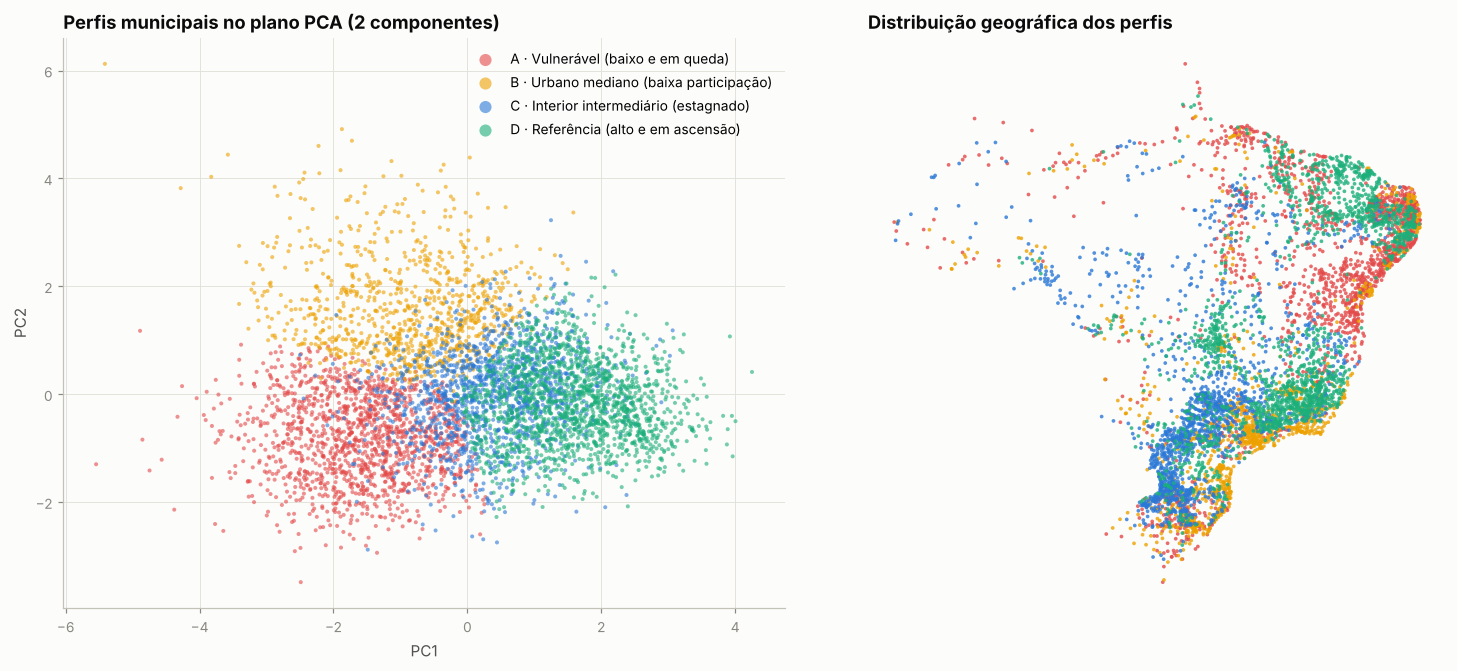

In [11]:
CORES_P = dict(zip([NOMES[c] for c in ordem_c], [vp.CAT[7], vp.CAT[3], vp.CAT[0], vp.CAT[2]]))
fig, axes = plt.subplots(1, 2, figsize=(14, 6.2))
for p, c in CORES_P.items():
    d = clusters[clusters.perfil == p]
    axes[0].scatter(d.pc1, d.pc2, s=7, alpha=0.6, color=c, label=p, edgecolors="none")
    axes[1].scatter(d.longitude, d.latitude, s=6, alpha=0.8, color=c, label=p, edgecolors="none")
axes[0].set(title="Perfis municipais no plano PCA (2 componentes)", xlabel="PC1", ylabel="PC2")
axes[0].legend(loc="upper right", markerscale=3)
axes[1].set_aspect("equal"); axes[1].grid(False); axes[1].set_xticks([]); axes[1].set_yticks([])
for sp in axes[1].spines.values(): sp.set_visible(False)
axes[1].set_title("Distribuição geográfica dos perfis")
fig.tight_layout(); vp.save(fig, "estr_clusters"); plt.show()

In [12]:
comp = pd.crosstab(clusters["perfil"], clusters["regiao"], normalize="columns").reindex(list(CORES_P)) * 100
comp.round(0)

regiao,Centro-Oeste,Nordeste,Norte,Sudeste,Sul
perfil,,,,,
A · Vulnerável (baixo e em queda),7.000,53.000,49.000,7.000,15.000
B · Urbano mediano (baixa participação),14.000,7.000,15.000,24.000,27.000
C · Interior intermediário (estagnado),33.000,5.000,28.000,29.000,46.000
D · Referência (alto e em ascensão),46.000,35.000,8.000,40.000,13.000


## 4. Metas futuras — trajetória até 2030

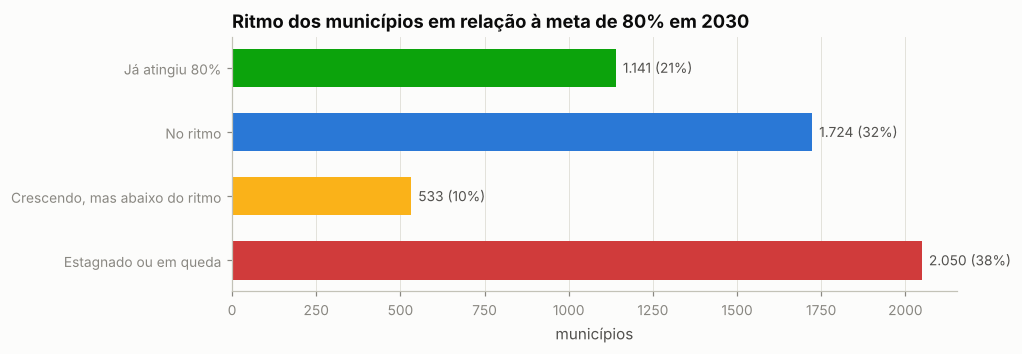

trajetoria_2030,Já atingiu 80%,No ritmo,"Crescendo, mas abaixo do ritmo",Estagnado ou em queda
perfil,,,,
A · Vulnerável (baixo e em queda),0.000,22.000,18.000,60.000
B · Urbano mediano (baixa participação),1.000,39.000,16.000,44.000
C · Interior intermediário (estagnado),12.000,34.000,6.000,47.000
D · Referência (alto e em ascensão),57.000,34.000,1.000,7.000


In [13]:
prof = clusters.copy()
prof["anos_restantes"] = 2030 - 2024
prof["crescimento_necessario_aa"] = prof["gap_meta_2030"].clip(lower=0) / prof["anos_restantes"]
obs = prof["evolucao_23_24"]
cat = np.select([prof["gap_meta_2030"] <= 0, obs >= prof["crescimento_necessario_aa"], obs > 0],
                ["Já atingiu 80%", "No ritmo", "Crescendo, mas abaixo do ritmo"], "Estagnado ou em queda")
prof["trajetoria_2030"] = cat
traj = prof["trajetoria_2030"].value_counts()
ordem_t = ["Já atingiu 80%", "No ritmo", "Crescendo, mas abaixo do ritmo", "Estagnado ou em queda"]
traj = traj.reindex(ordem_t)
fig, ax = plt.subplots(figsize=(8.5, 3))
cores_t = [vp.STATUS["Baixo"], vp.CAT[0], vp.STATUS["Moderado"], vp.STATUS["Crítico"]]
ax.barh(traj.index[::-1], traj.values[::-1], color=cores_t[::-1], height=0.6)
for i, v in enumerate(traj.values[::-1]): ax.text(v + 20, i, f"{v:,} ({v / traj.sum():.0%})".replace(",", "."), va="center", fontsize=9, color=vp.INK2)
ax.set(title="Ritmo dos municípios em relação à meta de 80% em 2030", xlabel="municípios"); ax.grid(axis="y", visible=False)
vp.save(fig, "estr_trajetoria_2030"); plt.show()
pd.crosstab(prof["perfil"], prof["trajetoria_2030"], normalize="index").reindex(columns=ordem_t).round(2) * 100

In [14]:
# Exporta a base consolidada para gestores (painel/planilha)
painel = ranking.merge(prof[["id_municipio", "perfil", "trajetoria_2030", "evolucao_23_24", "gap_meta_2030"]], on="id_municipio", how="left")
painel.to_csv(config.REPORTS_DIR / "painel_gestores_municipios.csv", index=False)
print(painel.shape, "→ reports/painel_gestores_municipios.csv")

(5448, 15) → reports/painel_gestores_municipios.csv


## 5. Respostas às perguntas de negócio

**Quais fatores mais impactam a alfabetização?** O histórico recente do município (taxa e proficiência), o engajamento da rede
(participação na avaliação) e o contexto estadual. Renda (PIB per capita) e porte têm papel secundário quando o histórico é conhecido:
**gestão educacional pesa mais que riqueza** — vários municípios do perfil *Referência* têm PIB per capita abaixo da mediana nacional.

**Quais municípios apresentam maior risco educacional?** Os de faixa *Crítico/Alto* no ranking 2025 — concentrados no **Sul** (sobretudo RS — efeito das
enchentes de 2024, com metas definidas antes do choque —, mas também PR e SC, que já haviam perdido a meta em 2024 em mais da metade
dos municípios), no **Norte** e em parte do **Nordeste** (BA, RN, MA, PB, SE). *Cautela:* o modelo foi treinado com uma única transição
(2023→2024); parte do risco do Sul é um efeito regional aprendido nesse ano e deve ser revisto quando sair o resultado de 2025. O ranking completo está em
`reports/ranking_risco_municipios_2025.csv`, com probabilidade, faixa, perfil e esforço necessário.

**Quais regiões possuem padrões semelhantes?** Quatro perfis — *Vulnerável*, *Urbano mediano*, *Interior intermediário* e *Referência* —
que **cortam as fronteiras regionais**: há municípios *Referência* no Nordeste e *Vulneráveis* no Sul. Isso sugere políticas por **perfil**,
não só por região, e redes de cooperação entre municípios parecidos (ex.: *Referência* do CE apoiando *Vulneráveis* do mesmo porte).

**Como prever municípios que podem não atingir metas futuras?** Com o classificador de risco (contexto do ano T → meta de T+1), re-treinado
a cada novo ciclo do Saeb, combinado com a **análise de trajetória** até 2030 (ritmo observado × ritmo necessário).

**Quais variáveis possuem maior influência nos modelos?** Modelo de alunos (SHAP/permutação): `mun_media_port_ant`, `mun_taxa_rede_ant`,
`mun_participacao_ant`, `uf_taxa_ant`. Modelo de risco municipal: taxa da UF, metas, proficiência média, porte e região.

### Recomendações para políticas públicas
1. **Focalização:** priorizar assistência técnica (formação de alfabetizadores, material estruturado) nos municípios *Crítico/Alto*,
   começando pelos de maior número de crianças.
2. **Plano de recuperação pós-desastre no RS:** recomposição de aprendizagem e revisão pactuada da trajetória de metas.
3. **Engajamento como alavanca:** metas de participação na avaliação (≥ 90%) — barato, acionável e associado a melhores resultados.
4. **Cooperação horizontal:** parear municípios *Referência* e *Vulnerável* de mesmo porte/UF (modelo "PAIC" do Ceará).
5. **Monitoramento contínuo:** re-treinar anualmente com a nova Gold e acompanhar o painel de risco/trajetória.